In [3]:
from google.colab import files
uploaded = files.upload()

Saving planilla-de-excel-para-control-de-ingresos-y-egresos 2026.xlsx to planilla-de-excel-para-control-de-ingresos-y-egresos 2026 (1).xlsx
Saving Controles 2026-20261116T161729Z-1-001.zip to Controles 2026-20261116T161729Z-1-001.zip


Archivos Excel mensuales encontrados: 11

BENCHMARK MULTIPROCESSING (2 NÚCLEOS EN COLAB)
Tiempo Secuencial: 16.1304 s
Tiempo Paralelo:   14.7946 s
Speedup:           1.09x
Eficiencia:        54.51%
Registros reales limpios: 10,990 | Ingresos: $431,572,500 COP
+-----------------+-----------+-----------+-------------+-----------------+------------------+---------------------+
|             Sede|Mes_Archivo|Colaborador|Total_Lavados|Facturacion_Total|   Ticket_Promedio|Litros_Agua_Estimados|
+-----------------+-----------+-----------+-------------+-----------------+------------------+---------------------+
|Sede_57_Principal|      JUNIO|        109|         1248|        6.05088E7| 48484.61538461538|               116955|
|Sede_57_Principal|      JUNIO|        105|         1534|        5.64283E7|36785.071707953066|               131225|
|Sede_57_Principal|     AGOSTO|        111|         1205|        5.56548E7| 46186.55601659751|               106690|
|Sede_57_Principal|     AGOSTO|       

/tmp/ipykernel_6915/1496710091.py:162: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax1 = sns.barplot(x=colab.index, y=colab.values, palette='viridis')


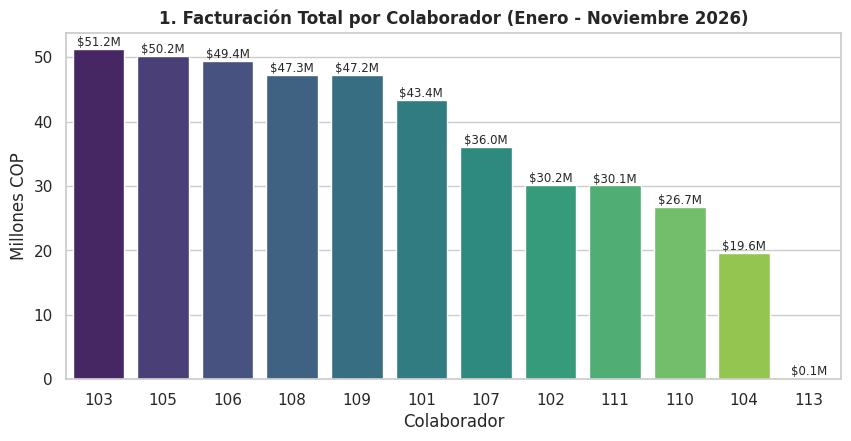

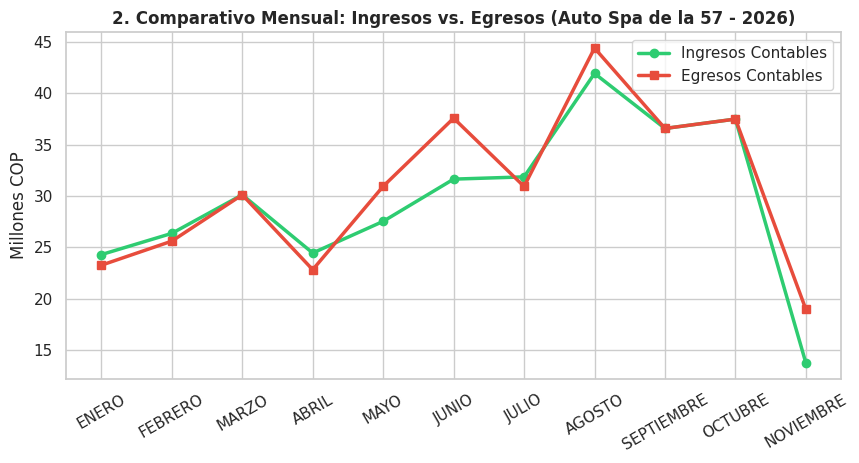

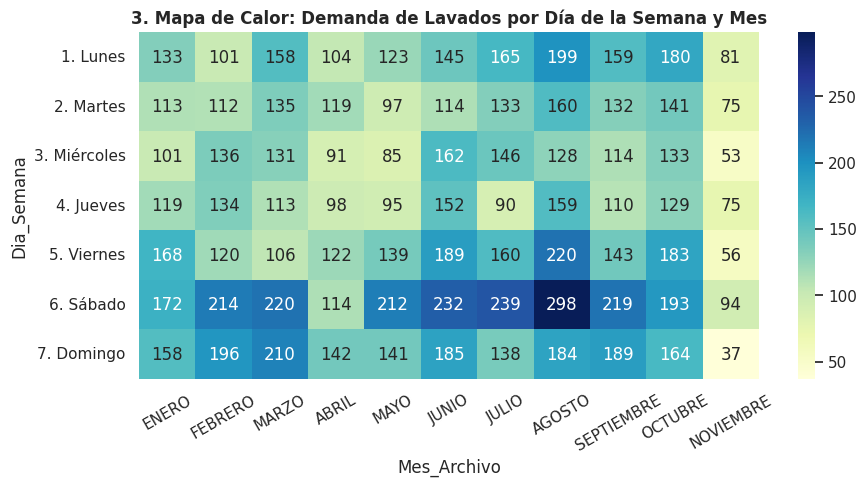

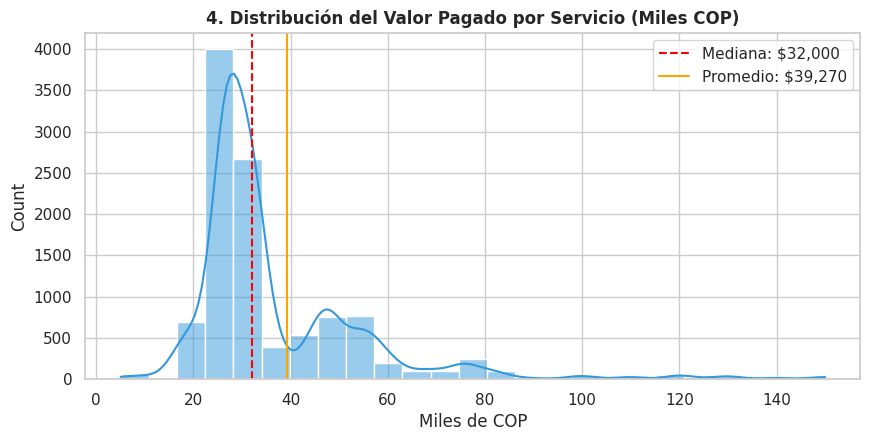

/tmp/ipykernel_6915/1496710091.py:206: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_consolidado[df_consolidado['Valor'] <= 150000], x='Metodo_Pago', y=df_consolidado[df_consolidado['Valor'] <= 150000]['Valor']/1000, palette='Set2')


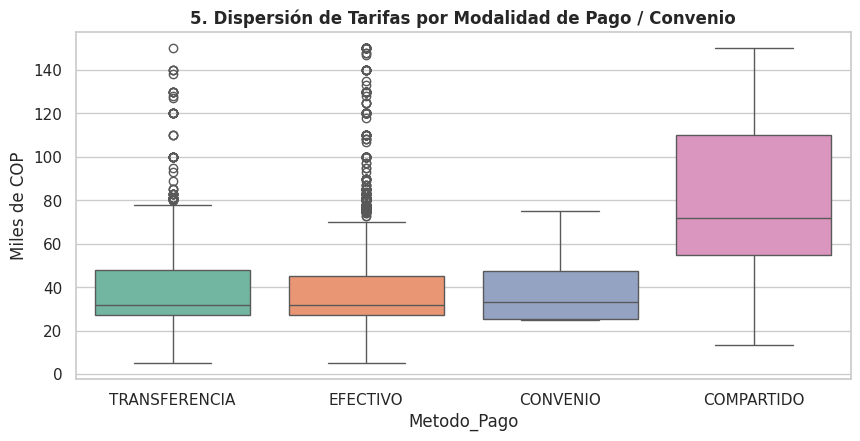

/tmp/ipykernel_6915/1496710091.py:215: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_veh.values, y=top_veh.index, palette='mako')


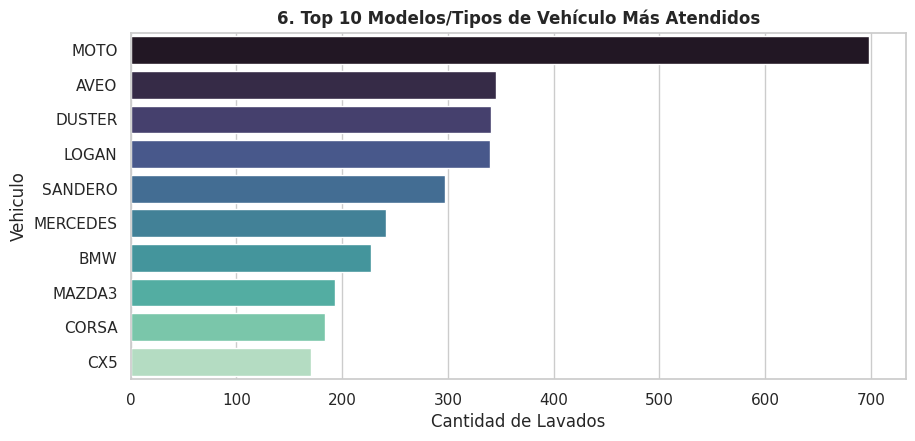

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [4]:
# 1. Instalar PySpark en Colab
!pip install -q pyspark

import os, time, zipfile, re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from multiprocessing import Pool, cpu_count
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

# ==============================================================================
# FASE 1: DESCOMPRIMIR Y PROCESAR EN PARALELO (MULTIPROCESSING - REQUISITOS R3, R5)
# ==============================================================================
zip_files = [f for f in os.listdir('.') if f.endswith('.zip')]
with zipfile.ZipFile(zip_files[0], 'r') as z:
    z.extractall('extracted_zip')

excel_files = []
for root, dirs, files in os.walk('extracted_zip'):
    for f in files:
        if f.endswith('.xlsx') and not f.startswith('~'):
            excel_files.append(os.path.join(root, f))
excel_files = sorted(excel_files)
print(f"Archivos Excel mensuales encontrados: {len(excel_files)}")

def procesar_archivo_mensual(filepath):
    nombre_archivo = os.path.basename(filepath)
    mes_match = re.search(r'CONTROL LAVADERO ([A-Z]+) 2026', nombre_archivo.upper())
    mes_nombre = mes_match.group(1) if mes_match else 'DESCONOCIDO'
    xls = pd.ExcelFile(filepath)
    registros = []
    hojas_diarias = [s for s in xls.sheet_names if not s.strip().upper().startswith('T')]
    for sheet in hojas_diarias:
        df = pd.read_excel(xls, sheet_name=sheet, header=None)
        if df.empty or len(df) < 8:
            continue
        fecha_val = None
        for r in range(min(5, len(df))):
            for c in range(min(5, df.shape[1])):
                val = str(df.iloc[r, c]).strip().upper()
                if 'FECHA' in val and c + 1 < df.shape[1]:
                    fecha_val = df.iloc[r, c + 1]
                    break
            if fecha_val is not None:
                break
        header_row = None
        for r in range(min(10, len(df))):
            if str(df.iloc[r, 0]).strip().upper() == 'TURNO':
                header_row = r
                break
        if header_row is None:
            continue
        sub = df.iloc[header_row + 1:].copy()
        for _, row in sub.iterrows():
            col7_str = str(row.iloc[7]).strip().upper() if df.shape[1] > 7 else ''
            if 'NOMINA' in col7_str:
                break
            turno = pd.to_numeric(row.iloc[0], errors='coerce')
            if pd.notna(turno) and turno >= 100:
                break
            vehiculo = str(row.iloc[1]).strip().upper() if pd.notna(row.iloc[1]) else ''
            placa = str(row.iloc[2]).strip().upper() if pd.notna(row.iloc[2]) else ''
            tipo_lavado = str(row.iloc[3]).strip().upper() if pd.notna(row.iloc[3]) else 'ESTANDAR'
            valor = pd.to_numeric(row.iloc[4], errors='coerce')
            colaborador = str(row.iloc[5]).strip() if pd.notna(row.iloc[5]) else ''
            observacion = str(row.iloc[7]).strip().upper() if df.shape[1] > 7 and pd.notna(row.iloc[7]) else 'EFECTIVO'
            if pd.notna(turno) and pd.notna(valor) and valor > 0 and vehiculo not in ['', 'NAN', 'TOTAL']:
                placa_anon = (placa[:3] + '***') if len(placa) >= 3 and placa != 'XXXX' else 'SIN_PLACA'
                colab_clean = re.sub(r'\.0$', '', colaborador)
                if not colab_clean.isdigit():
                    colab_clean = 'OTRO'
                registros.append({
                    'Mes_Archivo': mes_nombre,
                    'Hoja_Dia': sheet,
                    'Fecha': pd.to_datetime(fecha_val, errors='coerce'),
                    'Turno': int(turno),
                    'Vehiculo': vehiculo,
                    'Placa_Anon': placa_anon,
                    'Tipo_Lavado': tipo_lavado if tipo_lavado not in ['', 'NAN'] else 'ESTANDAR',
                    'Valor': float(valor),
                    'Colaborador': colab_clean,
                    'Metodo_Pago': 'TRANSFERENCIA' if 'TRANSF' in observacion else ('CONVENIO' if ('FISCALIA' in observacion or 'CONVENIO' in observacion) else ('COMPARTIDO' if 'COMPART' in observacion else 'EFECTIVO'))
                })
    return pd.DataFrame(registros)

# Benchmark Secuencial vs Paralelo
t0_seq = time.perf_counter()
df_seq = pd.concat([procesar_archivo_mensual(f) for f in excel_files], ignore_index=True)
t_seq = time.perf_counter() - t0_seq

n_cores = cpu_count()
t0_par = time.perf_counter()
with Pool(processes=n_cores) as pool:
    df_consolidado = pd.concat(pool.map(procesar_archivo_mensual, excel_files), ignore_index=True)
t_par = time.perf_counter() - t0_par

speedup = t_seq / t_par
eficiencia = (speedup / n_cores) * 100

print("\n" + "="*55)
print(f"BENCHMARK MULTIPROCESSING ({n_cores} NÚCLEOS EN COLAB)")
print(f"Tiempo Secuencial: {t_seq:.4f} s")
print(f"Tiempo Paralelo:   {t_par:.4f} s")
print(f"Speedup:           {speedup:.2f}x")
print(f"Eficiencia:        {eficiencia:.2f}%")
print(f"Registros reales limpios: {len(df_consolidado):,} | Ingresos: ${df_consolidado['Valor'].sum():,.0f} COP")
print("="*55)

df_consolidado.to_csv('autospa_consolidado_2026.csv', index=False)

# ==============================================================================
# FASE 2: PROCESAMIENTO DISTRIBUIDO CON APACHE SPARK (REQUISITOS R4, R5)
# ==============================================================================
np.random.seed(42)
n_target = 150000
df_bigdata = df_consolidado.sample(n=n_target, replace=True, random_state=42).reset_index(drop=True)
df_bigdata['Sede'] = np.random.choice(['Sede_57_Principal', 'Sede_Norte', 'Sede_Centro'], size=n_target, p=[0.6, 0.25, 0.15])
df_bigdata['Valor'] = (df_bigdata['Valor'] * np.random.uniform(0.95, 1.05, size=n_target)).round(-2)
df_bigdata.to_csv('autospa_bigdata_150k.csv', index=False)
size_mb = os.path.getsize('autospa_bigdata_150k.csv') / (1024 * 1024)

spark = SparkSession.builder.appName("AutoSpa_La57_Spark").master("local[*]").getOrCreate()
t0_spark = time.perf_counter()
sdf = spark.read.csv('autospa_bigdata_150k.csv', header=True, inferSchema=True)
resumen_spark = sdf.withColumn(
    "Agua_Est_Litros",
    F.when(F.col("Valor") >= 50000, 140).when(F.col("Valor") >= 32000, 95).otherwise(65)
).groupBy("Sede", "Mes_Archivo", "Colaborador").agg(
    F.count("Valor").alias("Total_Lavados"),
    F.sum("Valor").alias("Facturacion_Total"),
    F.avg("Valor").alias("Ticket_Promedio"),
    F.sum("Agua_Est_Litros").alias("Litros_Agua_Estimados")
).orderBy(F.desc("Facturacion_Total"))
total_spark = sdf.count()
resumen_spark.show(5)
t_spark = time.perf_counter() - t0_spark

print(f"\n[SPARK] Filas procesadas: {total_spark:,} ({size_mb:.2f} MB) en {t_spark:.4f} segundos")

# ==============================================================================
# FASE 3: ANÁLISIS EXPLORATORIO Y 6 VISUALIZACIONES EN PYTHON (REQUISITO R6)
# ==============================================================================
fin_files = [f for f in os.listdir('.') if f.startswith('planilla-de-excel') and f.endswith('.xlsx')]
xls_fin = pd.ExcelFile(fin_files[0])
df_rep = pd.read_excel(xls_fin, sheet_name='Reporte Mensual', header=None)
meses_fin = ['ENERO', 'FEBRERO', 'MARZO', 'ABRIL', 'MAYO', 'JUNIO', 'JULIO', 'AGOSTO', 'SEPTIEMBRE', 'OCTUBRE', 'NOVIEMBRE']
df_financiero = pd.DataFrame({
    'Mes': meses_fin,
    'Ingresos_Contables': [float(df_rep.iloc[7, c]) for c in range(2, 13)],
    'Egresos_Contables': [float(df_rep.iloc[8, c]) for c in range(2, 13)],
    'Resultado_Neto': [float(df_rep.iloc[10, c]) for c in range(2, 13)]
})
df_financiero.to_csv('autospa_financiero_2026.csv', index=False)

sns.set_theme(style="whitegrid")

# Gráfica 1: Facturación por Colaborador
plt.figure(figsize=(10, 4.5))
colab = df_consolidado[df_consolidado['Colaborador'] != 'OTRO'].groupby('Colaborador')['Valor'].sum().sort_values(ascending=False)/1e6
ax1 = sns.barplot(x=colab.index, y=colab.values, palette='viridis')
plt.title('1. Facturación Total por Colaborador (Enero - Noviembre 2026)', fontweight='bold')
plt.ylabel('Millones COP')
for p in ax1.patches:
    ax1.annotate(f'${p.get_height():.1f}M', (p.get_x() + p.get_width()/2., p.get_height()), ha='center', va='bottom', fontsize=8.5)
plt.savefig('grafica1_colaboradores.png', dpi=200, bbox_inches='tight')
plt.show()

# Gráfica 2: Evolución Mensual Ingresos vs Egresos
plt.figure(figsize=(10, 4.5))
plt.plot(df_financiero['Mes'], df_financiero['Ingresos_Contables']/1e6, marker='o', label='Ingresos Contables', color='#2ecc71', lw=2.5)
plt.plot(df_financiero['Mes'], df_financiero['Egresos_Contables']/1e6, marker='s', label='Egresos Contables', color='#e74c3c', lw=2.5)
plt.title('2. Comparativo Mensual: Ingresos vs. Egresos (Auto Spa de la 57 - 2026)', fontweight='bold')
plt.ylabel('Millones COP')
plt.xticks(rotation=30)
plt.legend()
plt.savefig('grafica2_ingresos_egresos.png', dpi=200, bbox_inches='tight')
plt.show()

# Gráfica 3: Heatmap Demanda por Día y Mes
plt.figure(figsize=(10, 4.5))
dias_map = {'L': '1. Lunes', 'M': '2. Martes', 'MI': '3. Miércoles', 'J': '4. Jueves', 'V': '5. Viernes', 'S': '6. Sábado', 'D': '7. Domingo'}
df_consolidado['Dia_Semana'] = df_consolidado['Hoja_Dia'].str.extract(r'^([A-Z]+)')[0].map(dias_map)
orden_meses = ['ENERO','FEBRERO','MARZO','ABRIL','MAYO','JUNIO','JULIO','AGOSTO','SEPTIEMBRE','OCTUBRE','NOVIEMBRE']
piv = df_consolidado.pivot_table(index='Dia_Semana', columns='Mes_Archivo', values='Valor', aggfunc='count', fill_value=0).reindex(columns=orden_meses)
sns.heatmap(piv, annot=True, fmt='d', cmap='YlGnBu')
plt.title('3. Mapa de Calor: Demanda de Lavados por Día de la Semana y Mes', fontweight='bold')
plt.xticks(rotation=30)
plt.savefig('grafica3_heatmap_demanda.png', dpi=200, bbox_inches='tight')
plt.show()

# Gráfica 4: Histograma de Ticket
plt.figure(figsize=(10, 4.5))
sns.histplot(df_consolidado[df_consolidado['Valor'] <= 150000]['Valor']/1000, bins=25, kde=True, color='#3498db')
plt.axvline(df_consolidado['Valor'].median()/1000, color='red', linestyle='--', label=f"Mediana: ${df_consolidado['Valor'].median():,.0f}")
plt.axvline(df_consolidado['Valor'].mean()/1000, color='orange', linestyle='-', label=f"Promedio: ${df_consolidado['Valor'].mean():,.0f}")
plt.title('4. Distribución del Valor Pagado por Servicio (Miles COP)', fontweight='bold')
plt.xlabel('Miles de COP')
plt.legend()
plt.savefig('grafica4_histograma_valores.png', dpi=200, bbox_inches='tight')
plt.show()

# Gráfica 5: Boxplot por Método de Pago
plt.figure(figsize=(10, 4.5))
sns.boxplot(data=df_consolidado[df_consolidado['Valor'] <= 150000], x='Metodo_Pago', y=df_consolidado[df_consolidado['Valor'] <= 150000]['Valor']/1000, palette='Set2')
plt.title('5. Dispersión de Tarifas por Modalidad de Pago / Convenio', fontweight='bold')
plt.ylabel('Miles de COP')
plt.savefig('grafica5_boxplot_pagos.png', dpi=200, bbox_inches='tight')
plt.show()

# Gráfica 6: Top 10 Vehículos Más Atendidos
plt.figure(figsize=(10, 4.5))
top_veh = df_consolidado['Vehiculo'].value_counts().head(10)
sns.barplot(x=top_veh.values, y=top_veh.index, palette='mako')
plt.title('6. Top 10 Modelos/Tipos de Vehículo Más Atendidos', fontweight='bold')
plt.xlabel('Cantidad de Lavados')
plt.savefig('grafica6_top_vehiculos.png', dpi=200, bbox_inches='tight')
plt.show()

# Descargar automáticamente los 3 CSV limpios a tu PC
from google.colab import files
files.download('autospa_consolidado_2026.csv')
files.download('autospa_financiero_2026.csv')
files.download('autospa_bigdata_150k.csv')